In [46]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import seaborn as sns
from sklearn.pipeline import Pipeline
from pca import pca
from sklearn.svm import SVC
import os
os.chdir("E:/Vishal_Adesh/CDAC/Machine Learning/Datasets")
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

In [47]:
df = pd.read_csv("../Day5/Vehicle.csv")
df

,Comp,Circ,D.Circ,Rad.Ra,Pr.Axis.Ra,Max.L.Ra,Scat.Ra,Elong,Pr.Axis.Rect,Max.L.Rect,Sc.Var.Maxis,Sc.Var.maxis,Ra.Gyr,Skew.Maxis,Skew.maxis,Kurt.maxis,Kurt.Maxis,Holl.Ra,Class
0,95,48,83,178,72,10,162,42,20,159,176,379,184,70,6,16,187,197,van
1,91,41,84,141,57,9,149,45,19,143,170,330,158,72,9,14,189,199,van
2,104,50,106,209,66,10,207,32,23,158,223,635,220,73,14,9,188,196,saab
3,93,41,82,159,63,9,144,46,19,143,160,309,127,63,6,10,199,207,van
4,85,44,70,205,103,52,149,45,19,144,241,325,188,127,9,11,180,183,bus
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
841,93,39,87,183,64,8,169,40,20,134,200,422,149,72,7,25,188,195,saab
842,89,46,84,163,66,11,159,43,20,159,173,368,176,72,1,20,186,197,van
843,106,54,101,222,67,12,222,30,25,173,228,721,200,70,3,4,187,201,saab
844,86,36,78,146,58,7,135,50,18,124,155,270,148,66,0,25,190,195,saab


In [48]:
X, y = df.drop("Class",axis =1), df["Class"]

In [49]:
scaler = StandardScaler().set_output(transform='pandas')
pca = PCA()
lr = LogisticRegression(random_state=26)
pipe = Pipeline([("SCL",scaler),("PCA",pca),("LR",lr)])

In [50]:
pipe.get_params()

{'memory': None,
 'steps': [('SCL', StandardScaler()),
  ('PCA', PCA()),
  ('LR', LogisticRegression(random_state=26))],
 'transform_input': None,
 'verbose': False,
 'SCL': StandardScaler(),
 'PCA': PCA(),
 'LR': LogisticRegression(random_state=26),
 'SCL__copy': True,
 'SCL__with_mean': True,
 'SCL__with_std': True,
 'PCA__copy': True,
 'PCA__iterated_power': 'auto',
 'PCA__n_components': None,
 'PCA__n_oversamples': 10,
 'PCA__power_iteration_normalizer': 'auto',
 'PCA__random_state': None,
 'PCA__svd_solver': 'auto',
 'PCA__tol': 0.0,
 'PCA__whiten': False,
 'LR__C': 1.0,
 'LR__class_weight': None,
 'LR__dual': False,
 'LR__fit_intercept': True,
 'LR__intercept_scaling': 1,
 'LR__l1_ratio': 0.0,
 'LR__max_iter': 100,
 'LR__n_jobs': None,
 'LR__penalty': 'deprecated',
 'LR__random_state': 26,
 'LR__solver': 'lbfgs',
 'LR__tol': 0.0001,
 'LR__verbose': 0,
 'LR__warm_start': False}

In [51]:
kfold = StratifiedKFold(random_state=26,shuffle=True)
params = { "PCA__n_components": np.arange(2,19),
          "LR__C":np.linspace(0.001,5,10)}
gcv = GridSearchCV(pipe, param_grid=params, cv=kfold, scoring="neg_log_loss")
gcv.fit(X,y)
print("Best Params: ",gcv.best_params_)
print("Best Score: ",gcv.best_score_)

Best Params:  {'LR__C': np.float64(5.0), 'PCA__n_components': np.int64(18)}
Best Score:  -0.4217087171493231


In [52]:
kfold = StratifiedKFold(random_state=26,shuffle=True)
params = { "PCA__n_components": [0.6,0.7,0.8,0.75,0.85,0.9], ## adding threshold
          "LR__C":np.linspace(0.001,5,10)}
gcv = GridSearchCV(pipe, param_grid=params, cv=kfold, scoring="neg_log_loss")
gcv.fit(X,y)
print("Best Params: ",gcv.best_params_)
print("Best Score: ",gcv.best_score_)

Best Params:  {'LR__C': np.float64(0.5564444444444444), 'PCA__n_components': 0.9}
Best Score:  -1.1411360597561164


In [53]:
from sklearn.decomposition import PCA

pca = PCA()  # Make sure this is an instantiated object, not a class reference

In [54]:
scaler = StandardScal er().set_output(transform='pandas')
svm = SVC(random_state=26,probability=True)
lr = LogisticRegression(random_state=26)
pipe = Pipeline([("SCL",scaler),("PCA",pca),("svm",svm)])

In [55]:
pipe.get_params()

{'memory': None,
 'steps': [('SCL', StandardScaler()),
  ('PCA', PCA()),
  ('svm', SVC(probability=True, random_state=26))],
 'transform_input': None,
 'verbose': False,
 'SCL': StandardScaler(),
 'PCA': PCA(),
 'svm': SVC(probability=True, random_state=26),
 'SCL__copy': True,
 'SCL__with_mean': True,
 'SCL__with_std': True,
 'PCA__copy': True,
 'PCA__iterated_power': 'auto',
 'PCA__n_components': None,
 'PCA__n_oversamples': 10,
 'PCA__power_iteration_normalizer': 'auto',
 'PCA__random_state': None,
 'PCA__svd_solver': 'auto',
 'PCA__tol': 0.0,
 'PCA__whiten': False,
 'svm__C': 1.0,
 'svm__break_ties': False,
 'svm__cache_size': 200,
 'svm__class_weight': None,
 'svm__coef0': 0.0,
 'svm__decision_function_shape': 'ovr',
 'svm__degree': 3,
 'svm__gamma': 'scale',
 'svm__kernel': 'rbf',
 'svm__max_iter': -1,
 'svm__probability': True,
 'svm__random_state': 26,
 'svm__shrinking': True,
 'svm__tol': 0.001,
 'svm__verbose': False}

In [56]:
kfold = StratifiedKFold(random_state=26,shuffle=True)
params = { "PCA__n_components": np.arange(2,19), ## adding threshold
          "svm__C":np.linspace(0.001,5,10)
         }
gcv = GridSearchCV(pipe, param_grid=params, cv=kfold, scoring="neg_log_loss")
gcv.fit(X,y)
print("Best Params: ",gcv.best_params_)
print("Best Score: ",gcv.best_score_)

Best Params:  {'PCA__n_components': np.int64(18), 'svm__C': np.float64(5.0)}
Best Score:  -0.3899338667442661


In [57]:
tsne = TSNE(random_state=26).set_output(transform='pandas')
t_comps = tsne.fit_transform(X)

In [58]:
t_comps

,tsne0,tsne1
0,-4.712229,10.084617
1,-20.005243,3.678526
2,33.672924,-2.252328
3,-23.543388,-7.075333
4,-6.514747,0.928207
...,...,...
841,1.270259,-9.241837
842,-6.424942,12.321892
843,53.694031,-3.373488
844,-32.796661,-7.702221


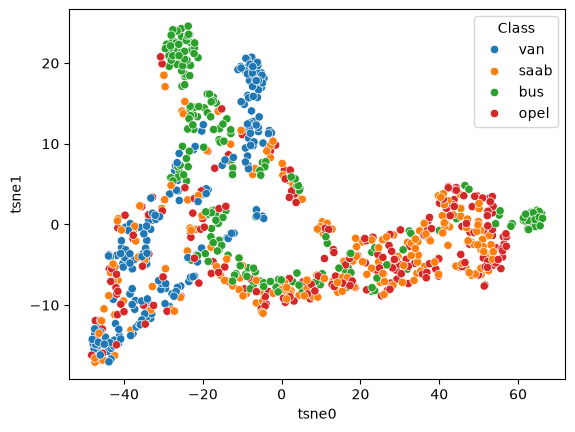

In [59]:
t_comps["Class"] = y
sns.scatterplot(x="tsne0",y="tsne1",hue="Class",data=t_comps)
plt.show()

#### Using Scaler

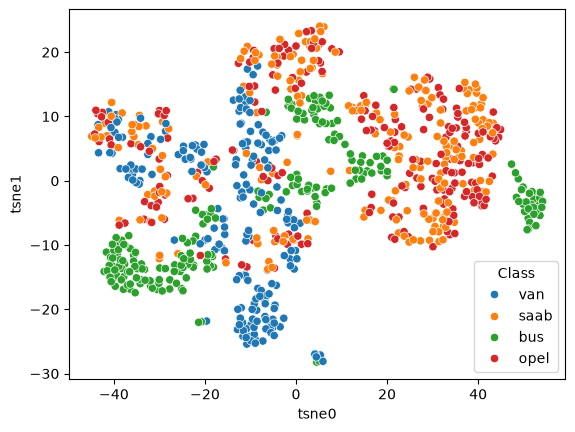

In [61]:
df = pd.read_csv("../Day5/Vehicle.csv")
df
X, y = df.drop("Class",axis =1), df["Class"]
scaler = StandardScaler().set_output(transform='pandas')
scl_x = scaler.fit_transform(X)
tsne = TSNE(random_state=26).set_output(transform='pandas')
t_comps = tsne.fit_transform(scl_x)
t_comps["Class"] = y
sns.scatterplot(x="tsne0",y="tsne1",hue="Class",data=t_comps)
plt.show()

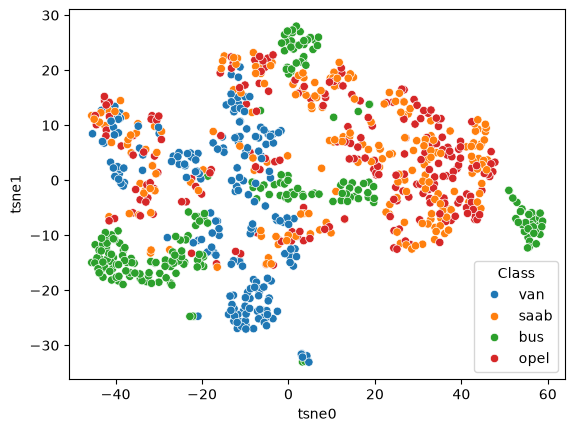

In [62]:
df = pd.read_csv("../Day5/Vehicle.csv")
df
X, y = df.drop("Class",axis =1), df["Class"]
scaler = StandardScaler().set_output(transform='pandas')
scl_x = scaler.fit_transform(X)
tsne = TSNE(random_state=26,perplexity=26).set_output(transform='pandas')
t_comps = tsne.fit_transform(scl_x)
t_comps["Class"] = y
sns.scatterplot(x="tsne0",y="tsne1",hue="Class",data=t_comps)
plt.show()